<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Pie Charts**
**IBM Skills Network guided lab | Portfolio edition**


### Project Overview
Developer surveys contain a wide range of responses about technology experience, professional roles, and future interests. In this notebook, I use pie charts to examine how frequently selected categories appear within different survey questions.

**Guiding question:** Which technologies and developer roles account for the largest shares of the most frequently reported responses?

**Approach:** Load the survey data, separate multi-select answers where necessary, count responses, create nine pie charts, and interpret the results.

**Tools and skills:** Python, Pandas, Matplotlib, data preparation, frequency analysis, and visual interpretation.

**How to read the percentages:** Most questions allow respondents to choose several answers. The pie charts display the share of mentions among the five most frequently mentioned categories, not the percentage of all survey respondents. A 30% slice does not mean 30% of developers selected that option.

*This notebook follows an IBM Skills Network guided lab. Original code, saved charts, instructional material, and attribution are preserved, with additional portfolio commentary.*

Estimated time needed: **30** minutes


### Objectives


In this lab you will perform the following:
-   Visualize the distribution of data.
-   Visualize the relationship between two features.
-   Visualize composition of data.
-   Visualize comparison of data.

### Setup: Downloading and Loading the Data
**Install the libraries**


In [3]:
!pip install pandas

In [1]:
!pip install matplotlib
!pip install seaborn

**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



In [5]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Step 2: Import necessary libraries and load the dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows to understand the structure of the data
df.head()

--2026-10-15 01:03:31--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv       0%[                    ]       0  --.-KB/s               
survey-data.csv       0%[                    ]  13.33K  21.8KB/s               
survey-data.csv       0%[                    ]   1.45M  1.17MB/s               
survey-data.csv       2%[                    ]   4.09M  2.40MB/s               
survey-data.csv       5%[>                   ]   7.77M  3.48MB/s               
survey-data.csv       7%[>             

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Visualizing Data Composition with Pie Charts


##### 1.1 Create a Pie Chart of the Top 5 Databases Respondents Want to Work With


In the survey data, the `DatabaseWantToWorkWith` column lists the databases that respondents wish to work with. Let’s visualize the top 5 most-desired databases in a pie chart. Each slice is a share of mentions among these five technologies, not a share of all respondents.


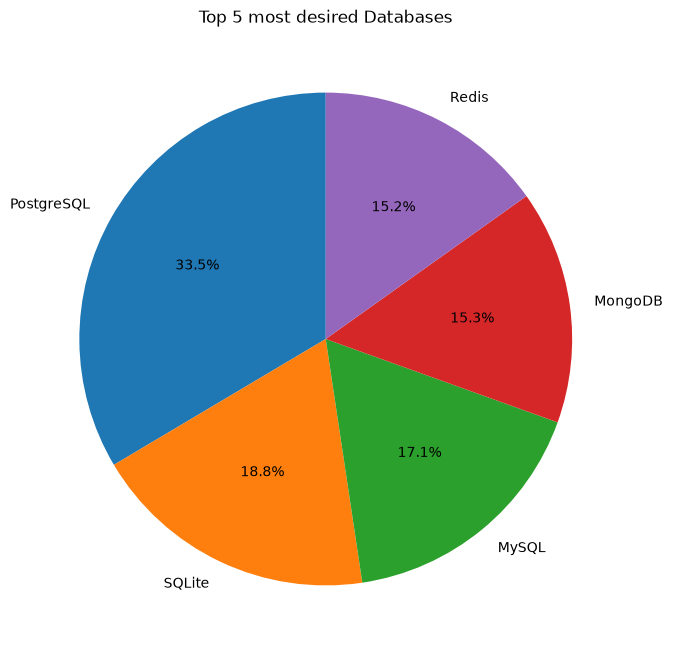

In [7]:
##Write your code here
df_db = df[['DatabaseWantToWorkWith']].dropna()
db_counts = df_db['DatabaseWantToWorkWith'].str.split(';').explode()
top_5_dbs = db_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_dbs, labels=top_5_dbs.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 most desired Databases')
plt.show()

PostgreSQL accounts for the largest share (33.5%) of mentions among the top five desired databases. SQLite follows at 18.8%, with MySQL (17.1%), MongoDB (15.3%), and Redis (15.2%) relatively close together.

PostgreSQL stands out within this selected group, while the remaining four technologies have more evenly distributed shares. This suggests stronger expressed interest in PostgreSQL among these leading options, not that one-third of all respondents want to use it.

The `DevType` column lists the developer types for respondents. We’ll examine the distribution by showing the top 5 developer roles in a pie chart.



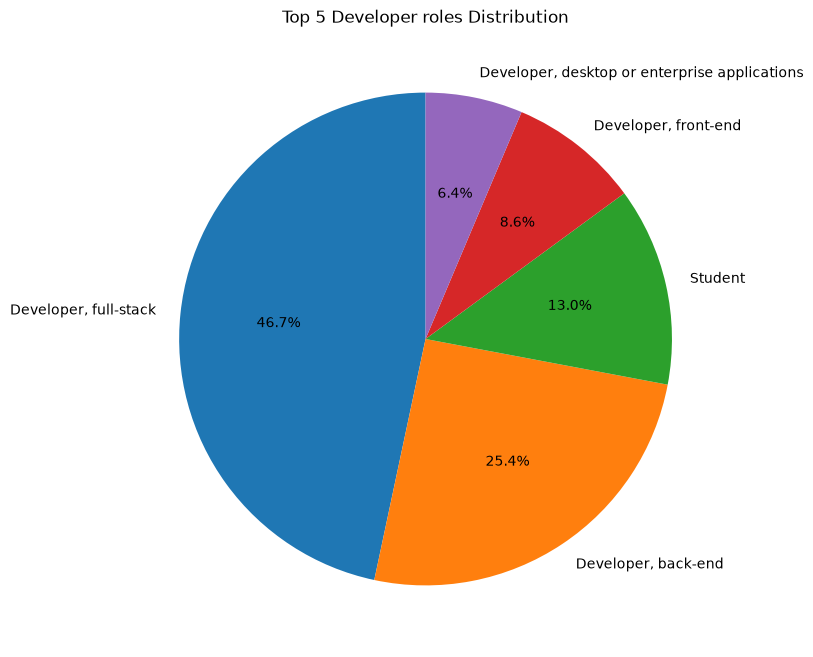

In [8]:
##Write your code here
df_dev = df[['DevType']].dropna()
dev_counts = df_dev['DevType'].str.split(';').explode()
top_5_dev = dev_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_dev, labels=top_5_dev.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 Developer roles Distribution')
plt.show()

Full-stack developers make up 46.7% of the mentions among the five displayed roles, followed by back-end developers at 25.4%. Students account for 13.0%, front-end developers for 8.6%, and desktop or enterprise application developers for 6.4%.

Full-stack and back-end development together account for roughly 72% of the selected categories. This highlights their prominence within the top-five breakdown, but the chart excludes other roles and should not be treated as the composition of the entire developer population.

##### 1.3 Create a pie chart for the operating systems used by respondents for professional use


The `OpSysProfessional` use column shows the operating systems developers use professionally. Let’s visualize the distribution of the top operating systems in a pie chart.



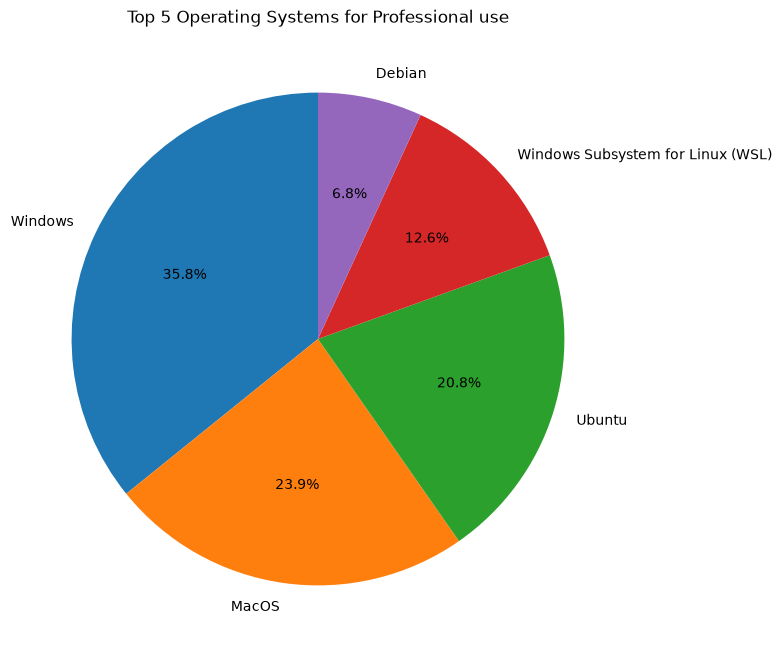

In [9]:
##Write your code here
df_opsys = df[['OpSysProfessional use']].dropna()
opsys_counts = df_opsys['OpSysProfessional use'].str.split(';').explode()
top_5_opsys = opsys_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_opsys, labels=top_5_opsys.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 Operating Systems for Professional use')
plt.show()

Windows has the largest share (35.8%) among the five displayed professional-use operating systems. macOS follows at 23.9%, Ubuntu at 20.8%, Windows Subsystem for Linux (WSL) at 12.6%, and Debian at 6.8%.

Windows leads this selected set, but macOS and Linux-related environments also feature prominently. The presence of WSL alongside Windows and Linux distributions reflects different ways developers may work across environments.

### Task 2: Additional Visualizations and Comparisons


##### 2.1 Pie Chart for Top 5 Programming Languages Respondents Have Worked With


The `LanguageHaveWorkedWith` column contains the programming languages that respondents have experience with. We’ll plot a pie chart to display the composition of the top 5 languages.



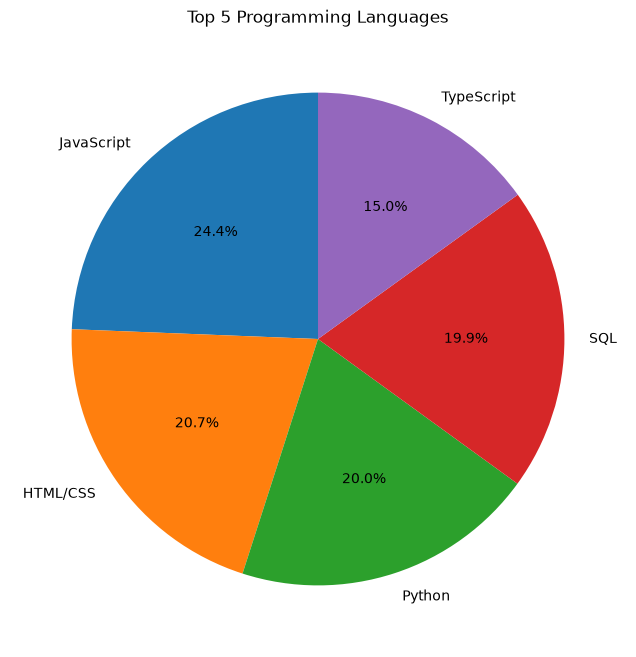

In [10]:
##Write your code here
df_lang = df[['LanguageHaveWorkedWith']].dropna()
lang_counts = df_lang['LanguageHaveWorkedWith'].str.split(';').explode()
top_5_langs = lang_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_langs, labels=top_5_langs.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 Programming Languages')
plt.show()

JavaScript leads the top five at 24.4%, followed by HTML/CSS (20.7%), Python (20.0%), SQL (19.9%), and TypeScript (15.0%). The shares of HTML/CSS, Python, and SQL are particularly close.

The chart shows that web-related languages and broadly used data or application-development languages all appear frequently in the saved survey results. JavaScript has the largest share within this selected group, but no single language accounts for a majority.

##### 2.2 Pie Chart for Top Collaboration Tools used in Professional Use


Using the `NEWCollabToolsHaveWorkedWith` column, we’ll identify and visualize the top collaboration tools respondents use in their professional work.



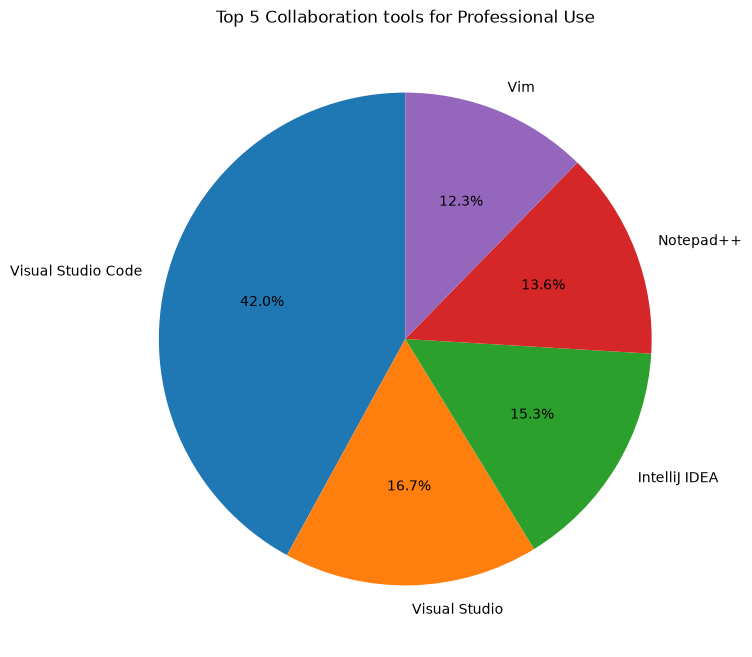

In [11]:
##Write your code here
df_tools = df[['NEWCollabToolsHaveWorkedWith']].dropna()
tools_counts = df_tools['NEWCollabToolsHaveWorkedWith'].str.split(';').explode()
top_5_tools = tools_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_tools, labels=top_5_tools.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 Collaboration tools for Professional Use')
plt.show()

Visual Studio Code dominates this selected group with 42.0% of mentions. Visual Studio follows at 16.7%, IntelliJ IDEA at 15.3%, Notepad++ at 13.6%, and Vim at 12.3%.

Visual Studio Code has a substantially larger share than any of the other four tools in this top-five comparison. This suggests that it is especially prominent among the recorded tool mentions.

### Task 3: Analyzing and Interpreting Composition


In this task, you will create additional pie charts to analyze specific aspects of the survey data. Use `pandas` and `matplotlib` to complete each task and interpret the findings.



##### 3.1 Pie Chart of `Respondents` Most Admired Programming Languages


The `LanguageAdmired` column lists the programming languages respondents admire most. Create a pie chart to visualize the top 5 admired languages.



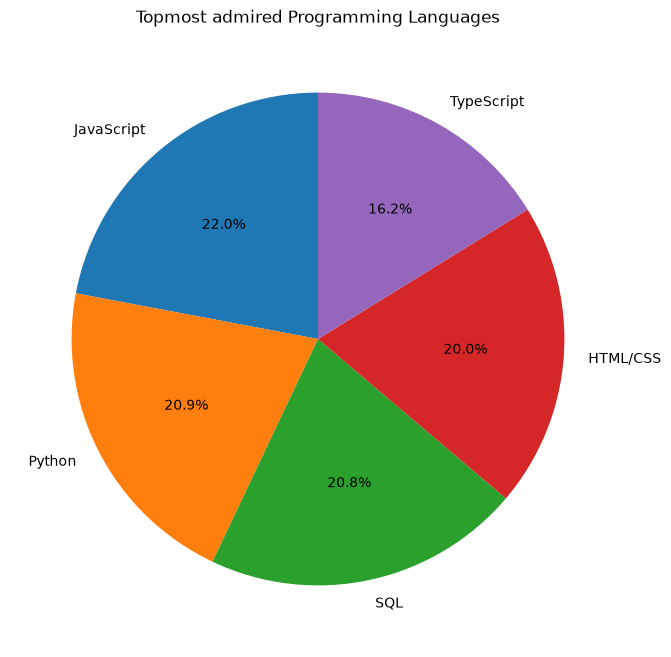

In [19]:
##Write your code here
df_admired = df[['LanguageAdmired']].dropna()
admired_counts = df_admired['LanguageAdmired'].str.split(';').explode()
top_admired = admired_counts.value_counts().head()

plt.figure(figsize=(8, 8))
plt.pie(top_admired, labels=top_admired.index, autopct='%1.1f%%', startangle=90)
plt.title('Topmost admired Programming Languages')
plt.show()

JavaScript accounts for 22.0% of mentions among the five most admired languages, followed closely by Python (20.9%), SQL (20.8%), and HTML/CSS (20.0%). TypeScript represents 16.2%.

Unlike the collaboration-tools chart, this distribution is relatively balanced. The four leading languages are separated by only about two percentage points, suggesting that admiration is spread across several widely used technologies within the selected set.

##### 3.2 Pie Chart of Tools Used for AI Development


Using the `AIToolCurrently` Using column, create a pie chart to visualize the top 5 tools developers are currently using for AI development.



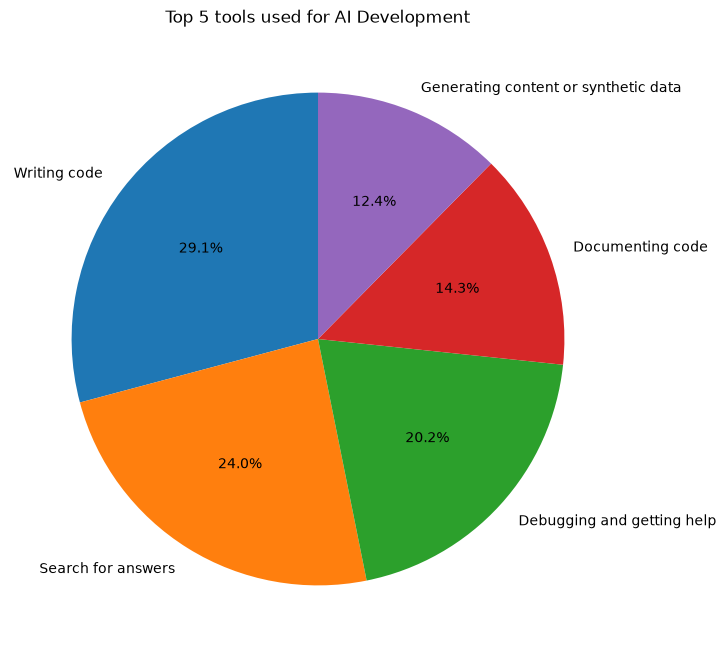

In [20]:
##Write your code here
df_ai = df[['AIToolCurrently Using']].dropna()
ai_counts = df_ai['AIToolCurrently Using'].str.split(';').explode()
top_ai = ai_counts.value_counts().head()

plt.figure(figsize=(8, 8))
plt.pie(top_ai, labels=top_ai.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 tools used for AI Development')
plt.show()

Writing code is the largest activity at 29.1% of mentions among the five displayed categories. Searching for answers follows at 24.0%, debugging and getting help at 20.2%, documenting code at 14.3%, and generating content or synthetic data at 12.4%.

The largest shares are associated with day-to-day development work: writing code, finding information, and troubleshooting. Together, these three categories account for approximately 73% of the selected activity mentions.

##### 3.3 Pie Chart for Preferred Web Frameworks


The `WebframeWantToWorkWith` column includes web frameworks that respondents are interested in working with. Visualize the top 5 frameworks in a pie chart.



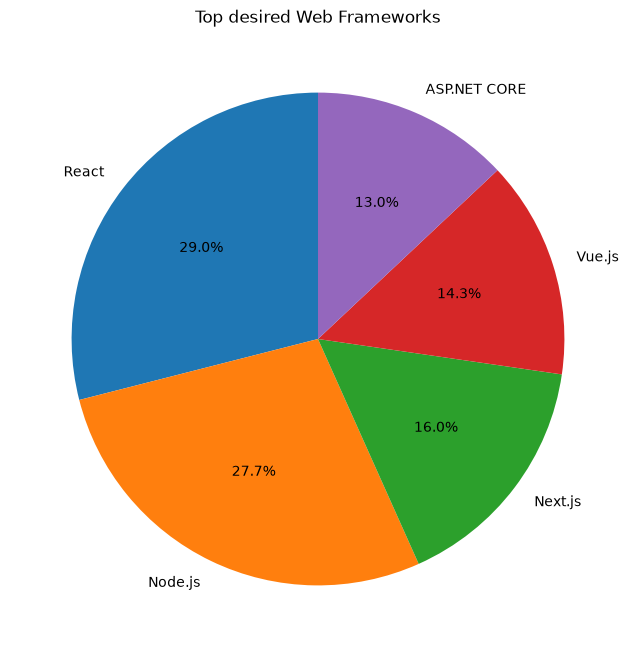

In [23]:
##Write your code here
df_web = df[['WebframeWantToWorkWith']].dropna()
web_counts = df_web['WebframeWantToWorkWith'].str.split(';').explode()
top_web = web_counts.value_counts().head(5)

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(top_web, labels=top_web.index, autopct='%1.1f%%', startangle=90)
plt.title('Top desired Web Frameworks')
plt.show()

React has the largest share (29.0%) among the five desired web frameworks, closely followed by Node.js at 27.7%. Next.js represents 16.0%, Vue.js 14.3%, and ASP.NET Core 13.0%.

React and Node.js together account for approximately 56.7% of the selected mentions. Their prominence indicates strong interest within this group of commonly requested technologies, while the remaining three frameworks also attract substantial mentions.

##### 3.4 Pie Chart for Most Desired Embedded Technologies


Using the `EmbeddedWantToWorkWith` column, create a pie chart to show the top 5 most desired embedded technologies that respondents wish to work with.



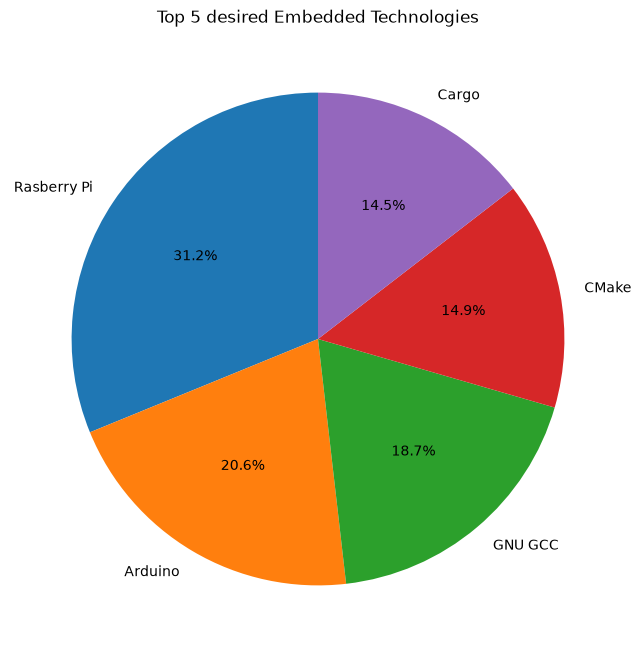

In [24]:
##Write your code here
df_embed = df[['EmbeddedWantToWorkWith']].dropna()
embed_counts = df_embed['EmbeddedWantToWorkWith'].str.split(';').explode()
top_5_embed = embed_counts.value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_embed, labels=top_5_embed.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 5 desired Embedded Technologies')
plt.show()

Raspberry Pi leads with 31.2% of mentions among the five displayed embedded technologies. Arduino follows at 20.6%, GNU GCC at 18.7%, CMake at 14.9%, and Cargo at 14.5%.

Raspberry Pi stands out as the most frequently mentioned option in this selected set. Arduino and GNU GCC form a middle group, while CMake and Cargo have very similar shares.

### Key Findings
Across the nine charts, several patterns emerge from the saved survey results:
- PostgreSQL has the largest share of mentions among the five most desired databases (33.5%).
- Full-stack development is the largest of the five displayed developer-role categories (46.7%).
- Windows leads the selected professional operating systems (35.8%).
- JavaScript leads the top-five currently used programming languages (24.4%), while the admired-language mentions are more evenly distributed.
- Visual Studio Code has a particularly strong share of the five most frequently mentioned development tools (42.0%).
- Writing code is the largest displayed AI-related activity (29.1%); these categories describe activities, not AI products.
- React and Node.js are close leaders among desired web frameworks (29.0% and 27.7%).
- Raspberry Pi leads the five selected embedded-development technologies (31.2%).

### Limitations and Next Steps
The most important limitation is the denominator: each pie chart shows percentages calculated from the top five mentions, not from all survey respondents. Many questions allow multiple answers, and some categories represent different kinds of technologies or activities. The charts therefore describe relative composition within selected responses, not exclusive market share or population-wide preferences.

For stronger comparisons, I would show the underlying counts, calculate the percentage of respondents selecting each option, and use bar charts when differences between categories are small. I would also compare current use and future interest using consistent definitions and denominators.

### Skills Demonstrated
- Data preparation: Filtering missing responses and separating multi-select answers.
- Data analysis: Counting category mentions and identifying the five most frequent responses.
- Visualization: Creating and interpreting pie charts with Pandas and Matplotlib.
- Communication: Explaining the findings, denominators, and limitations in clear, evidence-based language.

### Summary


After completing this lab, you will be able to:
- Create pie charts to visualize developer preferences across databases, programming languages, AI tools, and cloud platforms.
- Identify trends in technology usage, role distribution, and tool adoption through pie charts.
- Analyze and compare data composition across various categories to gain insights into developer preferences.

*Attribution: The original IBM Skills Network lab, logo, instructional content, and copyright remain intact. The project overview and chart-by-chart analysis were added for portfolio presentation.*

### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
